**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 Operaciones de aprendizaje automático (Gpo 10)**

Tecnológico de Monterrey

Prof Iván Reyes Amezcua

Semana 3 Actividad | Dataset - Notebook | Individual

NOMBRE: Jessica Paola Ruiz Cruz

MATRÍCULA: A00823322

# Fase: EDA (análisis exploratorio)

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

## Paso 1: Carga y describe el dataset

**Estructura del dataset**

* **Número de registros:** 1,143
* **Número de variables:** 12 (11 fisicoquímicas, 1 de calidad y 1 identificador)
* **Tipos de datos:** 11 variables `float64` y 1 variables `int64`
* **Valores nulos:** 0
* **Registros duplicados:** 125 (al excluir el `Id`, que es único en cada fila)

**Indicadores**

* `Id` (índice): Identificador único de cada registro, sin significado fisicoquímico; se usa como índice del DataFrame
* `fixed acidity`: Ácidos no volátiles del vino, principalmente tartárico, que no se evaporan fácilmente (g/dm³) — `float64`
* `volatile acidity`: Cantidad de ácido acético; en exceso produce un sabor avinagrado (g/dm³) — `float64`
* `citric acid`: Cantidad de ácido cítrico, que aporta frescura y sabor (g/dm³) — `float64`
* `residual sugar`: Azúcar que permanece en el vino después de la fermentación (g/dm³) — `float64`
* `chlorides`: Cantidad de sal (cloruro de sodio) presente en el vino (g/dm³) — `float64`
* `free sulfur dioxide`: Dióxido de azufre libre, que actúa como antioxidante y antimicrobiano (mg/dm³) — `float64`
* `total sulfur dioxide`: Dióxido de azufre total, suma del libre y el combinado (mg/dm³) — `float64`
* `density`: Densidad del vino, que depende del alcohol y del azúcar (g/cm³) — `float64`
* `pH`: Nivel de acidez del vino; a menor valor, mayor acidez (escala de 0 a 14) — `float64`
* `sulphates`: Sulfatos añadidos como aditivo para la conservación del vino (g/dm³) — `float64`
* `alcohol`: Contenido de alcohol del vino (% vol) — `float64`
* `quality`: Calificación de calidad del vino, variable objetivo (valores enteros de 3 a 8) — `int64`
* `Id`: Identificador único de cada registro, sin significado fisicoquímico — `int64`

In [2]:
wine_df=pd.read_csv('wine_quality_df.csv')
wine_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## Paso 2: Realiza un análisis exploratorio (EDA):
**Estadísticas descriptivas y distribución de las variables**

In [3]:
wine_df = pd.read_csv('wine_quality_df.csv', index_col='Id')
wine_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Id,,,,,,,,,,,,
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
wine_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1143 entries, 0 to 1597
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 116.1 KB


In [5]:
#Duplicados
print(wine_df.isna().sum())
print("Duplicados:", wine_df.duplicated().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Duplicados: 125


No se encontraron valores nulos en ninguna de las 12 columnas. Sí se detectaron 125 registros duplicados (mismos valores en las 11 variables y en `quality`), que se tratarán en la etapa de limpieza.

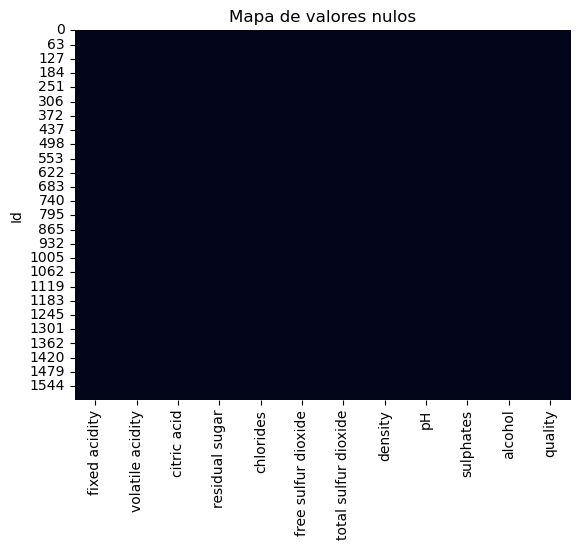

In [6]:
#Valores nulos"
sns.heatmap(wine_df.isna(), cbar=False)
plt.title('Mapa de valores nulos')
plt.show()

Se encuentran 1,143 filas y 12 columnas: 11 variables fisicoquímicas del vino, quality (entero de 3 a 8) e
Id. No hay nulos ni duplicados, y todas las columnas son numéricas.

In [7]:
dup = wine_df[wine_df.duplicated(keep=False)]
dup.sort_index().head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Id,,,,,,,,,,,,
0,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
64,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5
86,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.9972,2.93,1.95,9.9,6
87,7.7,0.490,0.26,1.90,0.062,9.0,31.0,0.9966,3.39,0.64,9.6,5
91,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.9972,2.93,1.95,9.9,6
93,7.7,0.490,0.26,1.90,0.062,9.0,31.0,0.9966,3.39,0.64,9.6,5
99,8.1,0.545,0.18,1.90,0.080,13.0,35.0,0.9972,3.30,0.59,9.0,6


In [8]:
wine_df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


Todas las variables son númericas, al ver estadisiticas descriptivas se noto de posibles outliers tomando en cuenta el min y máx y verificand junto con la media. Se elimino ID, ya que no es una variable del vino.

In [9]:
Q1 = wine_df.quantile(0.25)
Q3 = wine_df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((wine_df < Q1 - 1.5 * IQR) | (wine_df > Q3 + 1.5 * IQR)).sum()
print(outliers.sort_values(ascending=False))

residual sugar          110
chlorides                77
fixed acidity            44
sulphates                43
total sulfur dioxide     40
density                  36
quality                  22
pH                       20
free sulfur dioxide      18
volatile acidity         14
alcohol                  12
citric acid               1
dtype: int64


residual sugar          110
chlorides                77
fixed acidity            44
sulphates                43
total sulfur dioxide     40
density                  36
pH                       20
free sulfur dioxide      18
volatile acidity         14
alcohol                  12
citric acid               1
dtype: int64


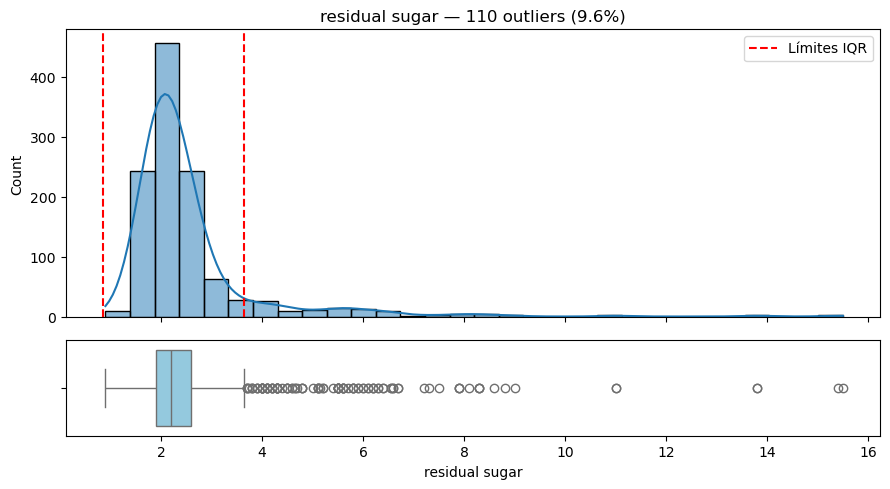

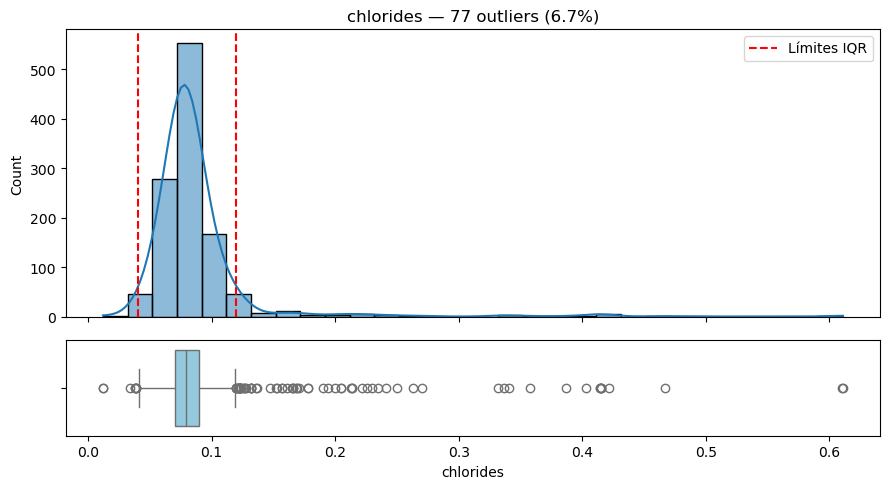

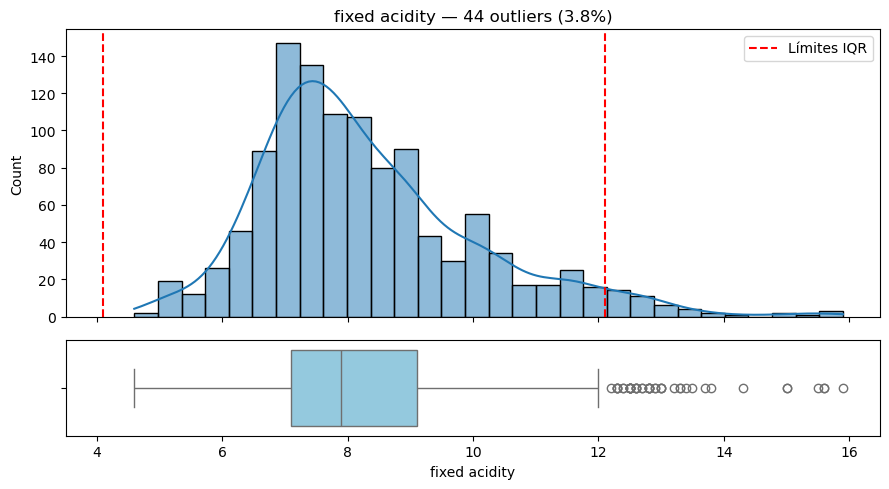

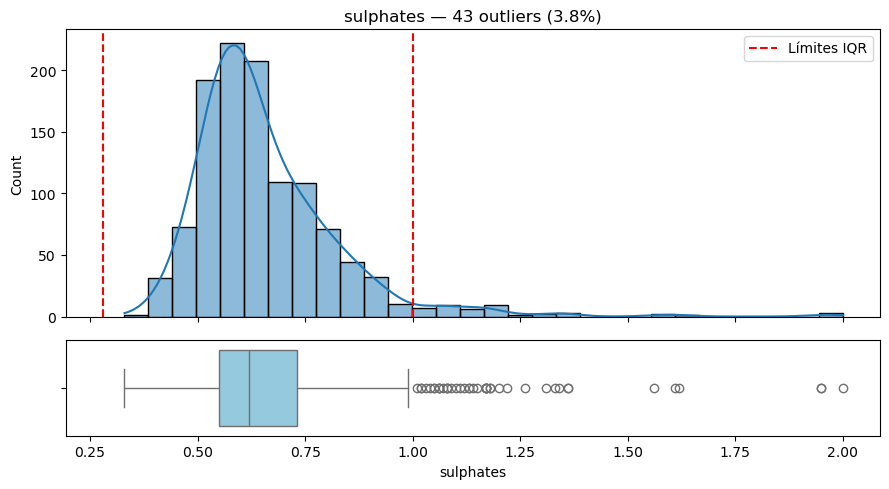

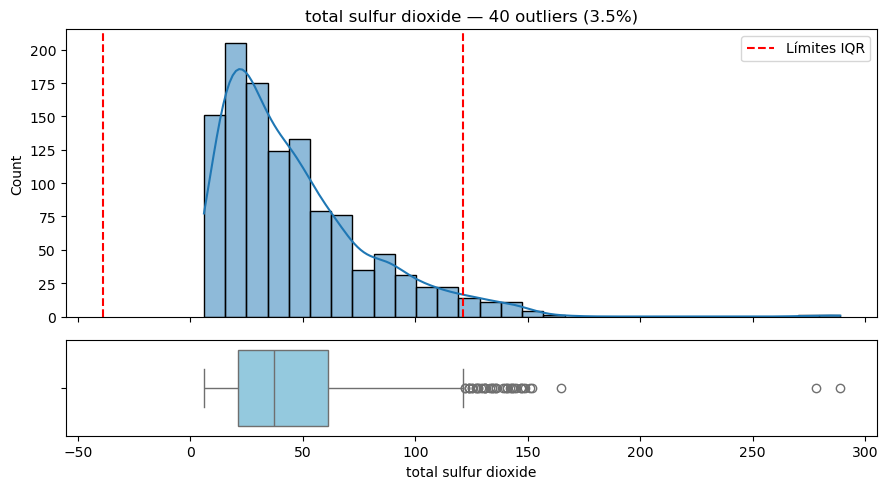

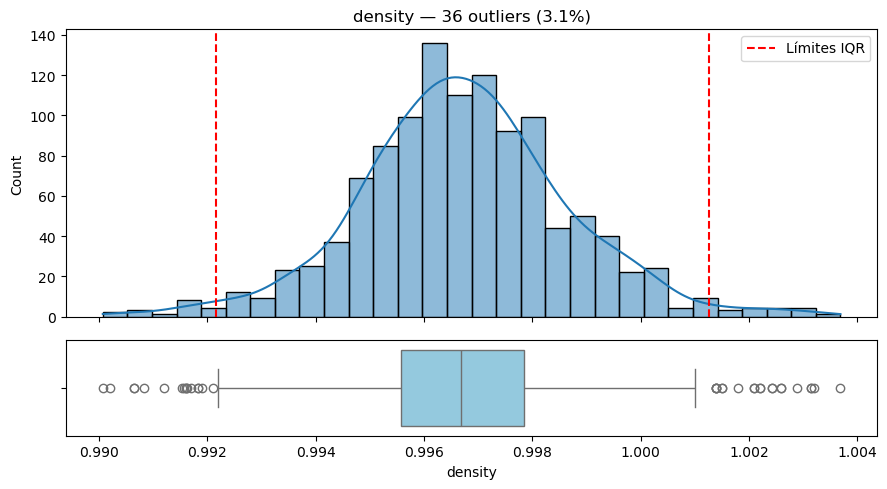

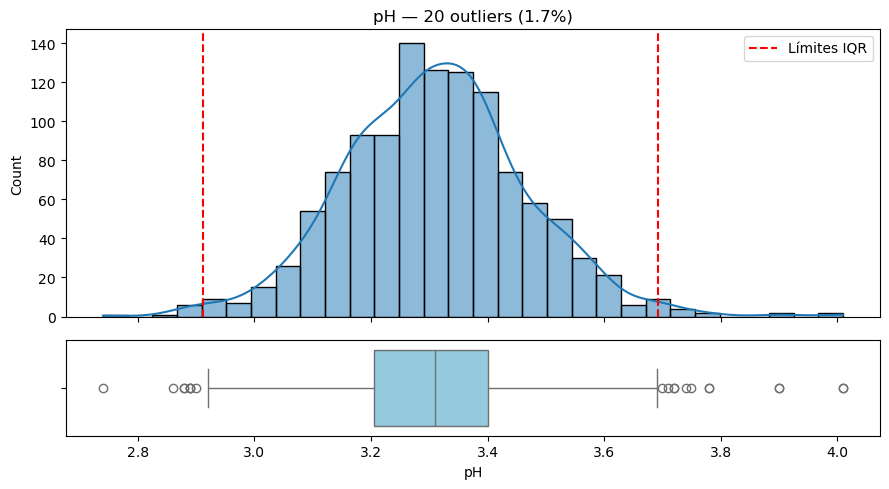

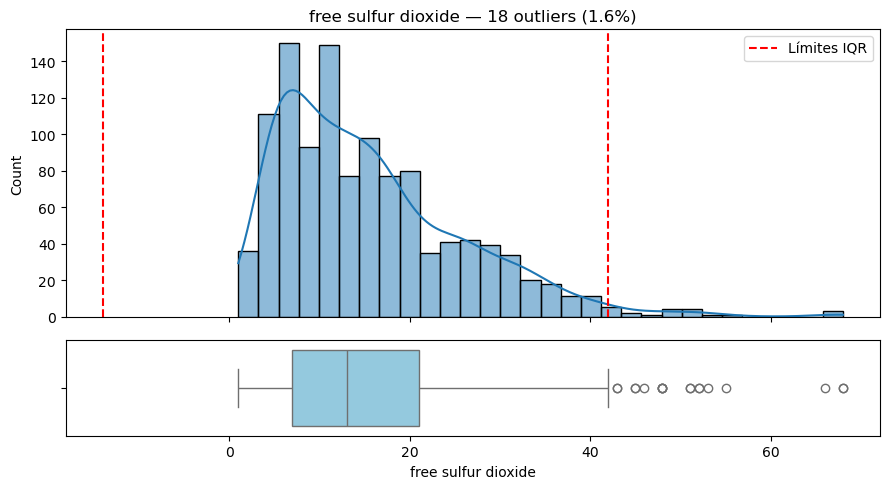

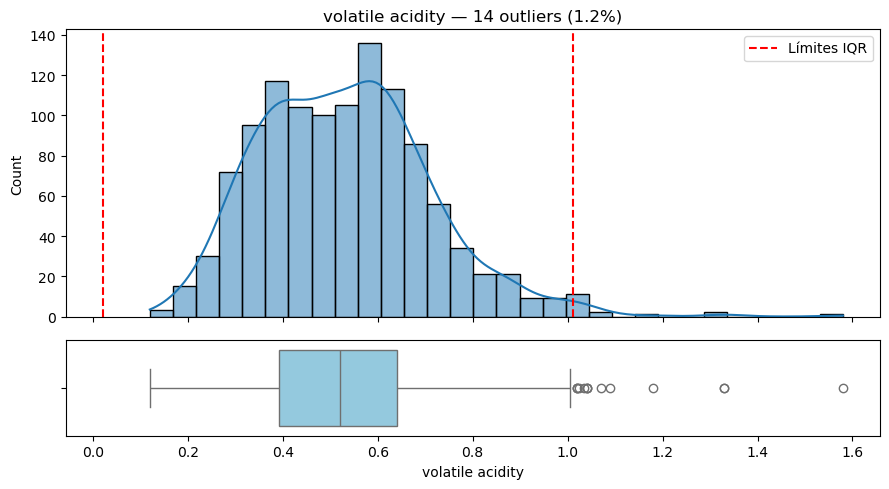

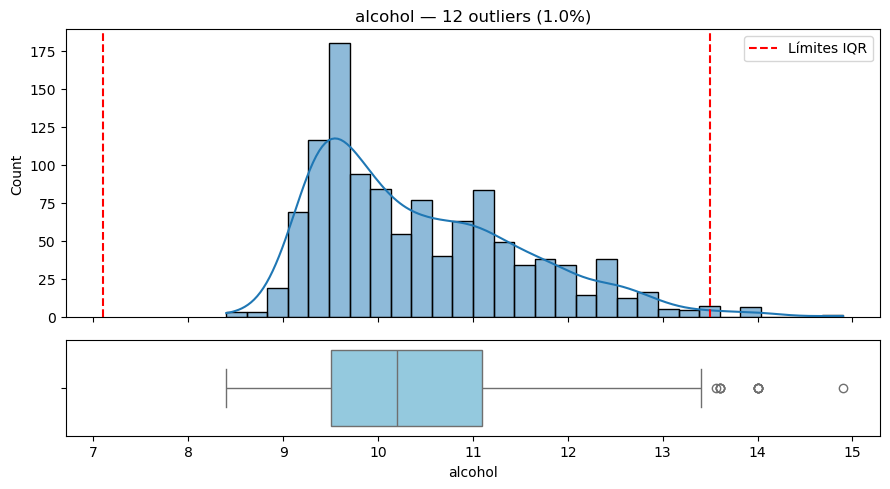

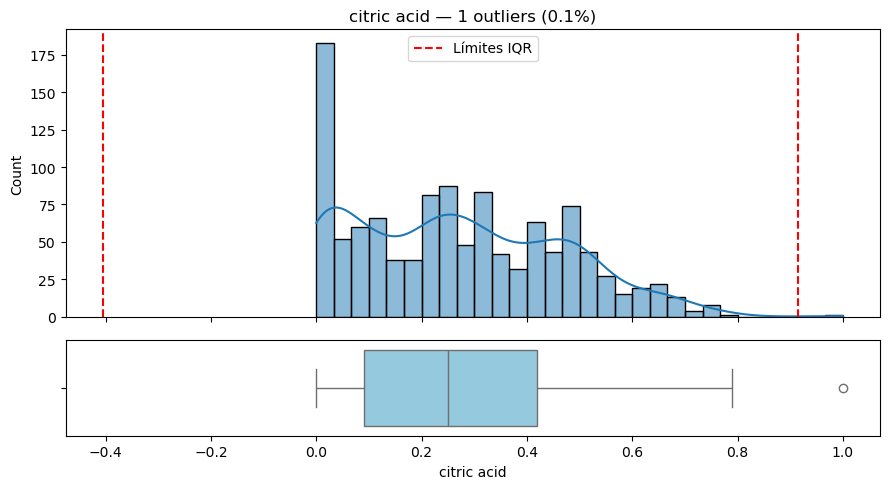

In [10]:
features = [c for c in wine_df.columns if c not in ('quality', 'Id')]

# 1. Límites IQR y conteo de outliers por variable
Q1 = wine_df[features].quantile(0.25)
Q3 = wine_df[features].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

n_outliers = ((wine_df[features] < lim_inf) | (wine_df[features] > lim_sup)).sum()
orden = n_outliers.sort_values(ascending=False)
print(orden)

# 2. Gráficos en ese orden
for col in orden.index:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})

    sns.histplot(wine_df[col], kde=True, bins=30, ax=ax1)
    ax1.axvline(lim_inf[col], color='red', linestyle='--', label='Límites IQR')
    ax1.axvline(lim_sup[col], color='red', linestyle='--')
    ax1.set_title(f'{col} — {orden[col]} outliers ({orden[col] / len(wine_df) * 100:.1f}%)')
    ax1.legend()

    sns.boxplot(x=wine_df[col], ax=ax2, color='skyblue')
    ax2.set_xlabel(col)

    plt.tight_layout()
    plt.show()

Descripción de histogramas y outliers:
1. Residual sugar (110 outliers, 9.6%)
Media: 2.53 g/L (mediana 2.2). La mayor parte de los datos está concentrada en torno a 2 g/L, con un pico muy alto y angosto. La cola derecha es larga y llega hasta 15.5, y eso empuja la media por encima de la mediana. En el boxplot, la caja casi no se ve, se encontraron outliers a partir de 3.65, con tres valores muy aislados cerca de 11, 13.7 y 15.5. Todos los outliers son altos.

2. Chlorides (77 outliers, 6.7%)
Media: 0.087 (mediana 0.079). Tiene un pico muy estrecho alrededor de 0.08 y una cola derecha extensa. Presenta outliers en ambos lados: unos pocos bajos (entre 0.01 y 0.04) y muchos altos. Destacan valores aislados entre 0.35 y 0.42, y uno en 0.61, muy alejado del resto.


3. Fixed acidity (44 outliers, 3.8%)
Media: 8.31 (mediana 7.9). Forma de campana con sesgo moderado a la derecha. El pico está entre 7 y 8, y la cola se extiende hacia 16. Los outliers son solo altos (arriba de 12.1) y van apareciendo de forma gradual, sin saltos grandes entre ellos.


4. Sulphates (43 outliers, 3.8%)
Media: 0.66 (mediana 0.62). El pico está alrededor de 0.6, con una cola derecha marcada. Los outliers son altos (arriba de 1.0), y hay cuatro puntos claramente separados del resto: dos cerca de 1.6 y dos en 2.0. Esos son los candidatos más sospechosos de la variable.


5. Total sulfur dioxide (40 outliers, 3.5%)
Media: 45.91 (mediana 37). El pico está entre 20 y 30, con una cola derecha larga. La diferencia de casi 9 puntos entre media y mediana refleja esa cola. Los outliers empiezan en 121 y se extienden hasta 289, con dos valores (cerca de 278 y 289) muy separados del resto. El límite inferior sale negativo (−39), por lo que no puede haber outliers bajos.


6. Density (36 outliers, 3.1%)
Media: 0.9967 (mediana 0.99668). Es una campana casi perfectamente simétrica: media y mediana prácticamente coinciden. Los outliers aparecen en los dos extremos (16 bajos y 20 altos) y están distribuidos sin grandes saltos. El rango es muy estrecho (0.990 a 1.004), por eso los valores del eje se ven tan pegados.


7. pH (20 outliers, 1.7%)
Media: 3.31 (mediana 3.31). También tiene forma de campana simétrica, con media y mediana idénticas. Sus outliers están en ambos lados: valores bajos desde 2.74 y altos hasta 4.01. Son pocos, sin agrupaciones extrañas, y parecen variaciones naturales.

8. Free sulfur dioxide (18 outliers, 1.6%)
Media: 15.62 (mediana 13). Tiene un sesgo a la derecha, con el pico entre 5 y 10 y la cola bajando gradualmente. Los 18 outliers están por encima de 42 y llegan a 68. Son menos extremos que en el dióxido de azufre total.

9. Volatile acidity (14 outliers, 1.2%)
Media: 0.53 (mediana 0.52). Distribución casi de campana, con un ligero sesgo a la derecha y una forma un poco irregular en la cima. Los outliers son solo altos (arriba de 1.01), con algunos valores aislados cerca de 1.3 y 1.58. Es la variable con mayor relación negativa con la calidad, así que esos vinos posiblemente sean de calidad baja.

10. Alcohol (12 outliers, 1.0%)
Media: 10.44 % (mediana 10.2). El pico está cerca de 9.5 y la distribución va cayendo hacia la derecha, con un sesgo visible. Los outliers son altos (arriba de 13.5, hasta 14.9), y son pocos y agrupados. Es la variable más relacionada con la calidad, por lo que esos vinos con más alcohol son informativos.

11. Citric acid (1 outlier, 0.1%)
Media: 0.27 (mediana 0.25). Es la más particular: tiene un pico muy alto justo en 0 (muchos vinos sin ácido cítrico) y, después, una distribución más dispersa con varias cimas entre 0.1 y 0.5. Solo hay un outlier, en 1.0, cerca del límite superior de 0.915. Aquí el dato a destacar no es el outlier sino la acumulación de valores en 0.


**Relación entre ellas**

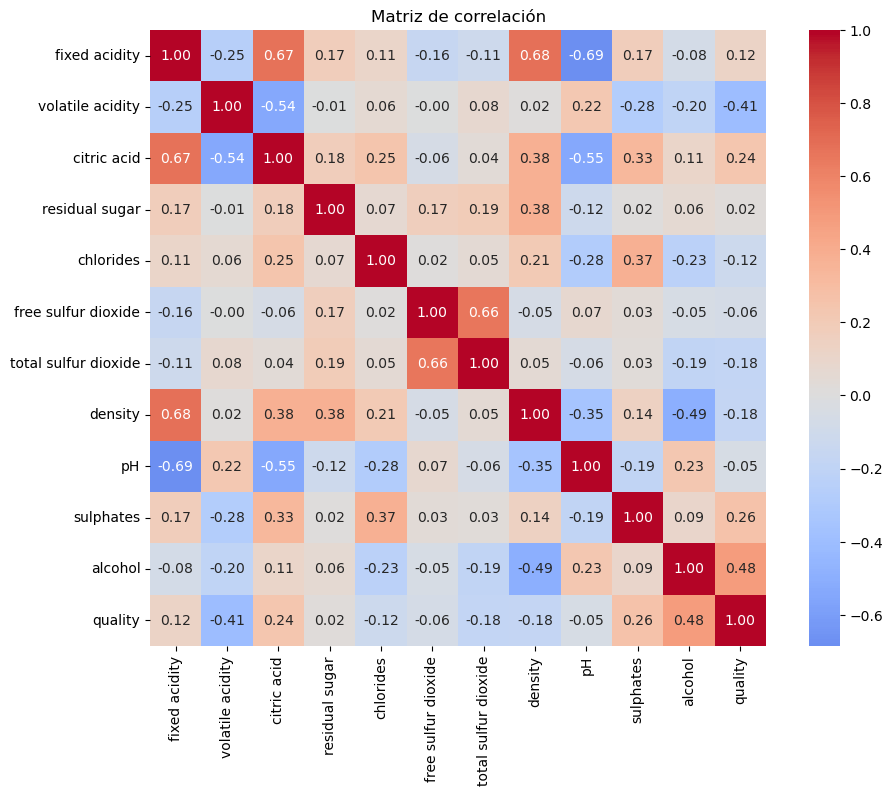

In [11]:
# Matriz de correlación (heatmap)
features = [c for c in wine_df.columns if c != 'Id']   # incluye quality

corr = wine_df[features].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Matriz de correlación')
plt.show()



- alcohol: Se determina que esta variable es la más fuerte con la varibale "quality" (+0.48), por lo que se que concluye que a mayor grado, mayor calidad.
- volatile acidity: A mayor acidez volátil, menor calidad.
- sulphates (+0.26) y citric acid (+0.24): Relación positiva débil.
- density (−0.18) y total sulfur dioxide (−0.18): Relación negativa débil.
- chlorides (−0.12) y fixed acidity (+0.12): Relación muy débil.
- free sulfur dioxide (−0.06), pH (−0.05) y residual sugar (+0.02): Prácticamente nula.

Ninguna variable supera 0.5, ninguna variable tiene una relación lineal suficientemente fuerte con la calidad por sí sola. Por eso, para predecir la calidad probablemente será necesario utilizar varias variables juntas. Además, una correlación cercana a cero solamente indica que no hay una relación lineal clara; todavía podría existir una relación no lineal.

Relaciones entre variables predictoras

Los pares con correlación alta (|r| ≥ 0.5) son:
- fixed acidity y density: +0.68
- fixed acidity y citric acid: +0.67
- fixed acidity y pH: −0.69
- free sulfur dioxide y total sulfur dioxide: +0.66
- citric acid y pH: −0.55
- volatile acidity y citric acid: −0.54

Interpretación:
- Acidez y pH: la relación negativa entre fixed acidity y pH (−0.69) es esperable, porque a más ácidos el pH baja. Lo mismo pasa con citric acid y pH.
- Azufre: el dióxido de azufre total incluye al libre, por eso están relacionados (0.66).
- Densidad y alcohol: el alcohol es menos denso que el agua, de ahí la correlación negativa (−0.49). Esto también explica parte de que density tenga una relación negativa con la calidad: gran parte de ese efecto viene del alcohol.
- Residual sugar: casi no se correlaciona con nada relevante, salvo con density (0.38), y tampoco con la calidad.

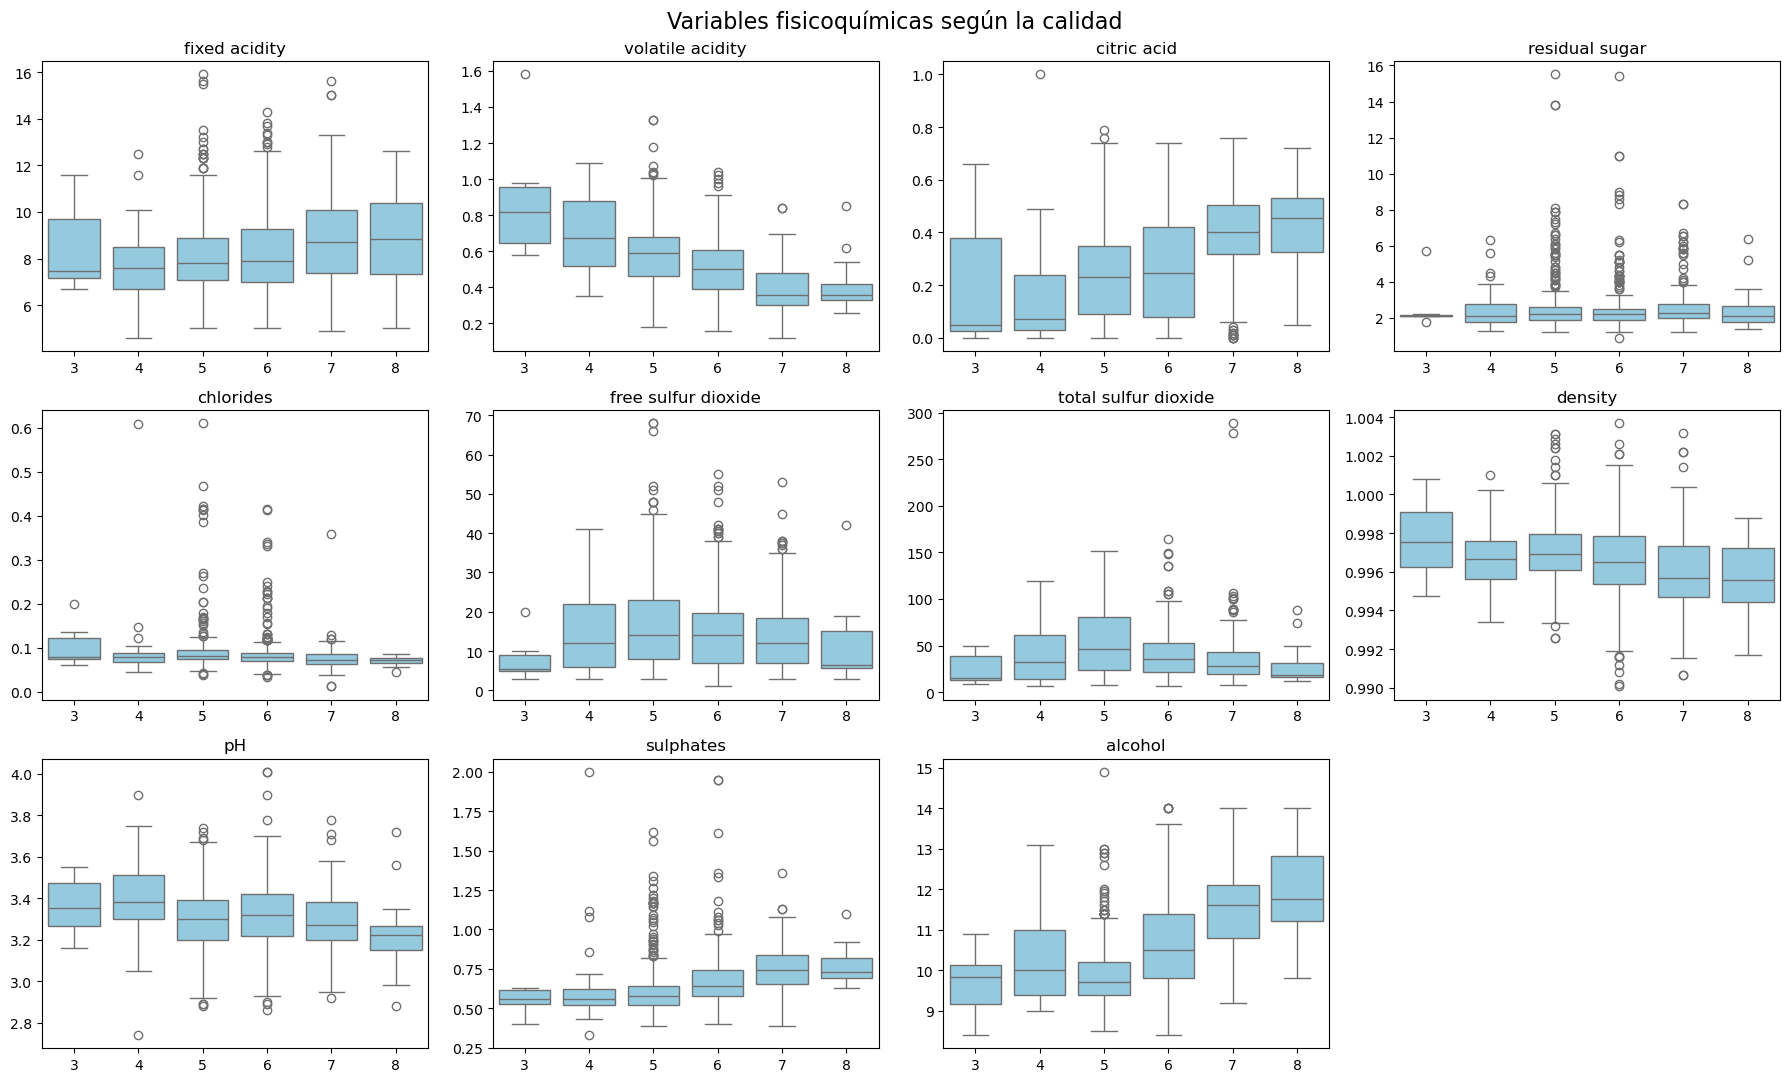

In [12]:
# Relación de cada variable con quality

vars_ = [c for c in features if c != 'quality']

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), vars_):
    sns.boxplot(x='quality', y=col, data=wine_df, ax=ax, color='skyblue')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('')
axes.ravel()[-1].axis('off')
plt.suptitle('Variables fisicoquímicas según la calidad', fontsize=16)
plt.tight_layout()
plt.show()

 Relación de las variables con la calidad (boxplots)

* **Variables con relación clara:** `alcohol` y `citric acid` aumentan con la calidad, mientras que `volatile acidity` y `density` disminuyen. `sulphates` también aumenta, sobre todo en las calidades 7 y 8.
* **Variables con relación débil o no lineal:** `fixed acidity`, `pH` y `chlorides` muestran cambios leves con mucho traslape entre categorías. `total sulfur dioxide` aumenta hasta la calidad 5 y luego disminuye.
* **Variables sin relación aparente:** `residual sugar` y `free sulfur dioxide` tienen medianas similares en casi todas las calidades.
* **Outliers:** se concentran en las calidades 5 y 6, que son las más frecuentes, y los valores más extremos aparecen repartidos en distintas calidades, por lo que no se consideran errores sistemáticos.
* **Limitación:** las calidades 3 y 8 tienen pocos registros (6 y 16), por lo que sus distribuciones son menos confiables.

---
**Siguientes etapas.** Este notebook se conserva únicamente para la exploración de datos (EDA). La limpieza (eliminación de los 125 duplicados), la división entrenamiento/prueba, el entrenamiento de los modelos, la evaluación y el registro en MLflow se encuentran en el script `train.py` del repositorio. Para ejecutarlo, consulta el `README.md`.